# 06 · The code from the common ancestor to the human repertoire

Every node on one time axis. The repertoire at relative time *t* is the set of lineages
crossing *t*: a branch leading to `v` occupies `[t(parent(v)), t(v))`, an internal node
contributes its ASR row and a tip its extant row. No order of receptor addition is needed.

Two time axes are used throughout. `mpl_times` makes the tree ultrametric by mean path
length (Britton et al. 2002) on the ingroup rooted at `node_1` (paper node 0); all 433 tips
are present-day genes, so non-ultrametricity is rate variation. Mean path length assumes rate
variation averages out, which is least safe when the rate difference is clade-level, as
between class I and class II, so `raw_times` (patristic depth, no clock) is drawn beside it:
read the shape, not the timing.

Calls are the density fill with no experimental overlay. `07` repeats the trajectory with the
measured M2OR values written over the extant rows; that version is Fig. 3g–i, and this one
supplies the raw-axis receptor counts of Fig. 3i (`results/trajectory_raw_axis.csv`).

In [1]:
import os
import sys
from pathlib import Path

REPO = Path("../..").resolve()
sys.path.append(str(REPO / "Downstream_Analysis/scripts"))
sys.path.append(str(REPO / "scripts"))

from ancestral_sets import (ASR_MATRIX, REF_MATRIX, PAIRS, FASTA, ASR_TREE, CLASSES,
                            FIGURES, TABLES)

INPUTS = [ASR_MATRIX, REF_MATRIX, PAIRS, FASTA, ASR_TREE, CLASSES]
TABLES_WRITTEN = ["clamped_nodes", "trajectory_without_measurements", "trajectory_raw_axis",
                  "founder_ligands", "composition_null", "independence_null",
                  "trajectory_blanked", "endpoint_overlay"]
FIGURES_WRITTEN = ["axis_diagnostics", "ultrametric_tree", "trajectory",
                   "standing_vs_cumulative", "founder_ligands", "composition_null",
                   "independence_null", "sensitivity_broad"]

for path in INPUTS:
    print("input  ", os.path.relpath(path, REPO))
print("tables ", os.path.relpath(TABLES, REPO), TABLES_WRITTEN)
print("figures", os.path.relpath(FIGURES, REPO), FIGURES_WRITTEN)

input   Downstream_Analysis/predictions/aggregated/ASR_Predictions/asr_median_probability_wide.csv
input   Downstream_Analysis/predictions/aggregated/Reference_Tree_Predictions/reference_median_probability_wide.csv
input   Model_Inputs/Data_Preparation/processed/m2or_pairs_model.csv
input   Phylogenetic_Analysis/data/ReferenceTree/PF13853.9606_7955_7740_7764_75743_137246.fa
input   Ancestral_Receptor_Reconstruction/human_tree_asr_hagfish_outgroup/PF13853_9606.7764.mafft.lg.treefile.rooted.withinternalnames
input   Phylogenetic_Analysis/data/HumanTree/human433_OR_classes.csv
tables  Downstream_Analysis/ancestral_receptors/results ['clamped_nodes', 'trajectory_without_measurements', 'trajectory_raw_axis', 'founder_ligands', 'composition_null', 'independence_null', 'trajectory_blanked', 'endpoint_overlay']
figures Downstream_Analysis/ancestral_receptors/figures ['axis_diagnostics', 'ultrametric_tree', 'trajectory', 'standing_vs_cumulative', 'founder_ligands', 'composition_null', 'independ

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from plotting_functions import custom_plots, FIGSIZE
from ancestral_sets import (mpl_times, raw_times, lineage_slice, class_clades, trajectory,
                            asr_tree, density_grid, overlay_grid, figure_node,
                            save_fig, save_table)
plt.rcParams.update(custom_plots())

COMMON_COL, CLASS1_COL, CLASS2_COL = "#5F6A72", "#7f1734", "#557c99"
BOTH_COL = "#b08a3e"          # odorants detected by both classes
NULL_COL = "#c9c9c4"

# one generator for the whole notebook; the nulls below draw from it in cell order
RNG = np.random.default_rng(0)

tree, index = asr_tree()
binary, prob, fills, ancestral = density_grid()
clades = class_clades()
classes = pd.read_csv(CLASSES)
leaf_class = dict(zip(classes.leaf_id, classes.OR_class))
extant_I = [k for k, v in leaf_class.items() if v == "Class_I"]
extant_II = [k for k, v in leaf_class.items() if v == "Class_II"]

print(f"grid           {binary.shape[0]} rows x {binary.shape[1]} ligands")
print(f"ASR fill       cut {fills['asr'].cut:.4f}   density {fills['asr'].density:.4%}")
print(f"extant fill    cut {fills['extant'].cut:.4f}   density {fills['extant'].density:.4%}")
print(f"class split    node_2 -> {len(clades['Class_I'] & set(leaf_class))} tips, "
      f"node_3 -> {len(clades['Class_II'] & set(leaf_class))} tips")

grid           865 rows x 754 ligands
ASR fill       cut 0.8875   density 2.2623%
extant fill    cut 0.8947   density 2.7453%
class split    node_2 -> 62 tips, node_3 -> 371 tips


## The time axis

Mean path length can return a child older than its parent; those nodes are clamped to the
parent's age (`results/clamped_nodes.csv`, with each violation as a fraction of root age).
The second panel shows how far ultrametricising moves each tip, by class.

root age 2.5604 substitutions/site
20 of 432 internal nodes clamped; worst violation 0.0371 of root age (node_100)
class II / class I median tip depth: raw 1.287, ultrametric 1.000


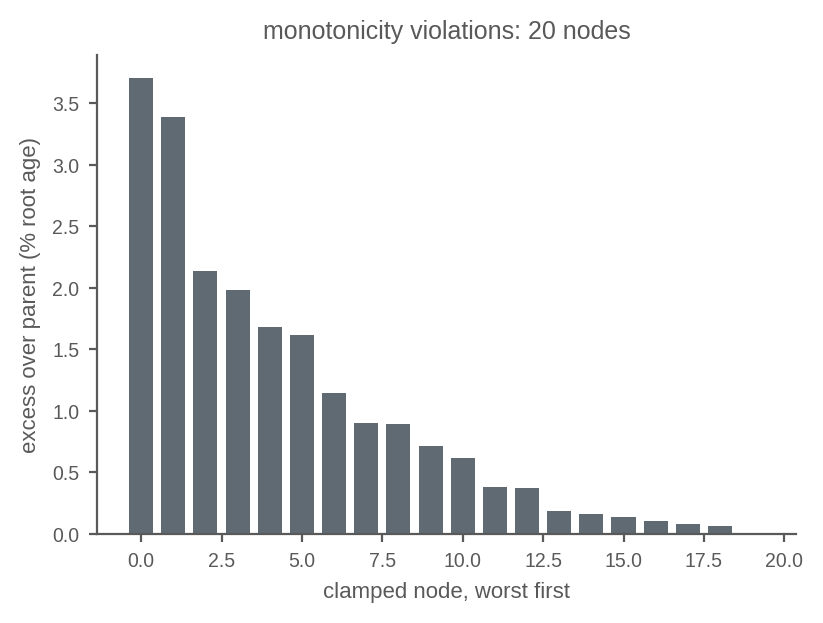

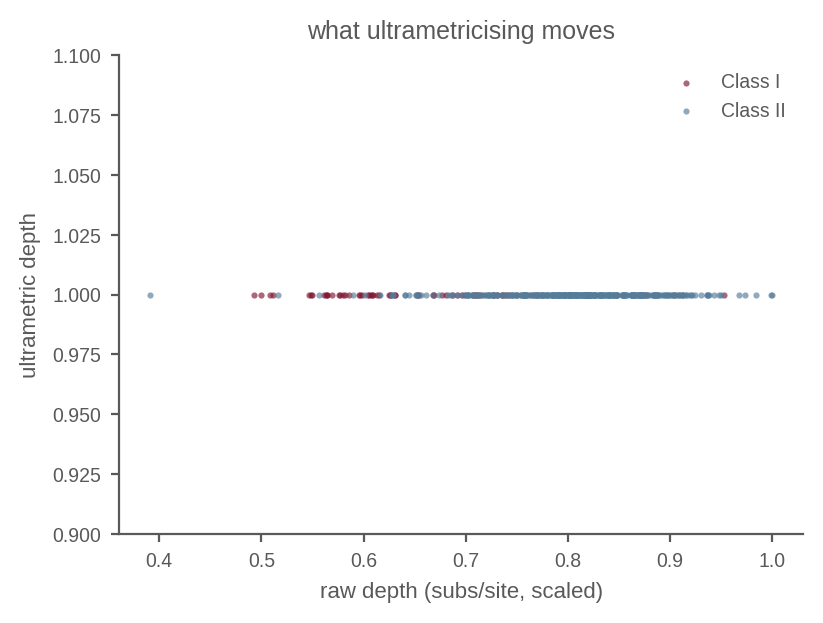

In [3]:
mpl = mpl_times()
raw = raw_times()
save_table(mpl.clamped, "clamped_nodes")
print(f"root age {mpl.root_age:.4f} substitutions/site")
print(f"{len(mpl.clamped)} of 432 internal nodes clamped; "
      f"worst violation {mpl.clamped.excess_frac_root_age.max():.4f} of root age "
      f"({mpl.clamped.node.iloc[0]})")

tips = [n.name for n in index["node_1"].leaves()]
depth_raw = {k: raw.t[k] for k in tips}
depth_mpl = {k: mpl.t[k] for k in tips}
ratio_raw = (np.median([depth_raw[k] for k in tips if leaf_class.get(k) == "Class_II"]) /
             np.median([depth_raw[k] for k in tips if leaf_class.get(k) == "Class_I"]))
ratio_mpl = (np.median([depth_mpl[k] for k in tips if leaf_class.get(k) == "Class_II"]) /
             np.median([depth_mpl[k] for k in tips if leaf_class.get(k) == "Class_I"]))
print(f"class II / class I median tip depth: raw {ratio_raw:.3f}, ultrametric {ratio_mpl:.3f}")

figures, axes = zip(*[plt.subplots(figsize=FIGSIZE, layout="constrained") for _ in range(2)])
ax = axes[0]
ax.bar(range(len(mpl.clamped)), mpl.clamped.excess_frac_root_age * 100,
       color=COMMON_COL, width=0.75)
ax.set_xlabel("clamped node, worst first"); ax.set_ylabel("excess over parent (% root age)")
ax.set_title(f"monotonicity violations: {len(mpl.clamped)} nodes", fontsize=9)
ax = axes[1]
for cls, col in [("Class_I", CLASS1_COL), ("Class_II", CLASS2_COL)]:
    members = [k for k in tips if leaf_class.get(k) == cls]
    ax.scatter([depth_raw[k] for k in members], [depth_mpl[k] for k in members],
               s=5, color=col, alpha=0.65, lw=0, label=cls.replace("_", " "))
ax.set_xlabel("raw depth (subs/site, scaled)"); ax.set_ylabel("ultrametric depth")
ax.set_ylim(0.9, 1.1); ax.legend(frameon=False, fontsize=7)
ax.set_title("what ultrametricising moves", fontsize=9)
save_fig(figures[0], "axis_diagnostics_clamped"); save_fig(figures[1], "axis_diagnostics_tip_depth"); plt.show()

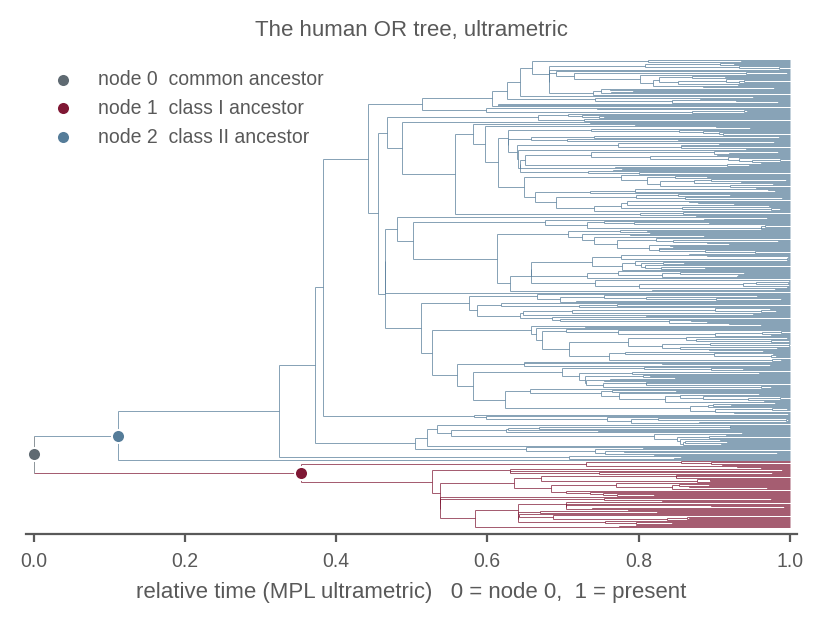

In [4]:
def layout(times, root="node_1"):
    """(x0, x1, y) for every branch, and the y-span of each internal node's children."""
    r = index[root]
    y = {}
    for i, leaf in enumerate(r.leaves()):
        y[leaf.name] = float(i)
    for n in r.traverse("postorder"):
        if not n.is_leaf:
            y[n.name] = float(np.mean([y[c.name] for c in n.children]))
    seg, vert = {}, {}
    for n in r.traverse():
        x1 = times.t[n.name]
        x0 = 0.0 if n is r else times.t[n.up.name]
        seg[n.name] = (x0, x1, y[n.name])
        if not n.is_leaf:
            vert[n.name] = (x1, min(y[c.name] for c in n.children),
                            max(y[c.name] for c in n.children))
    return seg, vert, y


def clade_colour(name):
    if name in clades["Class_I"]:
        return CLASS1_COL
    if name in clades["Class_II"]:
        return CLASS2_COL
    return COMMON_COL


def draw_tree(ax, times, lw=0.18, root="node_1"):
    seg, vert, y = layout(times, root)
    for name, (x0, x1, yy) in seg.items():
        ax.plot([x0, x1], [yy, yy], color=clade_colour(name), lw=lw, solid_capstyle="butt")
    for name, (x, lo, hi) in vert.items():
        ax.plot([x, x], [lo, hi], color=clade_colour(name), lw=lw, solid_capstyle="butt")
    n_leaves = sum(1 for k in y if index[k].is_leaf)
    ax.set_ylim(-6, n_leaves + 6)
    ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    return seg, y


fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
seg, ypos = draw_tree(ax, mpl, lw=0.25)
for name, label, col in [("node_1", "node 0  common ancestor", COMMON_COL),
                         ("node_2", "node 1  class I ancestor", CLASS1_COL),
                         ("node_3", "node 2  class II ancestor", CLASS2_COL)]:
    x, yy = mpl.t[name], ypos[name]
    ax.scatter([x], [yy], s=22, color=col, zorder=5, edgecolor="white", lw=0.7, label=label)
ax.legend(loc="upper left")          # the three nodes sit close together, so they are named in a legend
ax.set_xlabel("relative time (MPL ultrametric)   0 = node 0,  1 = present")
ax.set_xlim(-0.01, 1.01)
ax.set_title("The human OR tree, ultrametric")
save_fig(fig, "ultrametric_tree"); plt.show()

## The trajectory

One row per node time on each axis: receptor lineages by class, odorants detected by class I
only, both classes or class II only, detectors per odorant, and the cumulative union of
odorants ever detected. Writes `results/trajectory_without_measurements.csv` (ultrametric axis) and
`results/trajectory_raw_axis.csv`. The standing count can fall as *t* increases, since
crossing a node replaces one lineage by its children; intermediate counts move by tens when a
single very broad lineage enters or leaves the slice, so the shape and the endpoints are the
result, not the intermediate integers.

In [5]:
traj = trajectory(mpl)
traj_raw = trajectory(raw)
save_table(traj, "trajectory_without_measurements")
save_table(traj_raw, "trajectory_raw_axis")

checkpoints = [0.0, 0.25, 0.50, 0.75, 0.83, 0.90, 0.96, 1.0]
view = pd.DataFrame([traj.iloc[(traj.t - q).abs().argmin()] for q in checkpoints])
print(view[["t", "n_class_I", "n_class_II", "n_detected", "cum_detected", "n_single",
            "n_combinatorial", "only_I", "both", "only_II"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4g}"))

     t  n_class_I  n_class_II  n_detected  cum_detected  n_single  n_combinatorial  only_I  both  only_II
     0          0           0          21            21        21                0       0     0        0
0.3246          1           3          40            47        31                9      18     3       19
0.5016          2          13          60            66        30               30      26     6       28
0.7505         26         113         535           536       103              432      21   237      277
0.8304         37         184         651           651        98              553      33   263      355
0.9004         54         251         657           657        88              569      32   318      307
0.9598         56         310         657           657        84              573      32   318      307
     1         62         371         668           671        50              618      15   342      311


largest step at t = 0.6475: 157 -> 373 odorants; broadest entering lineage node_125 (288 ligands)


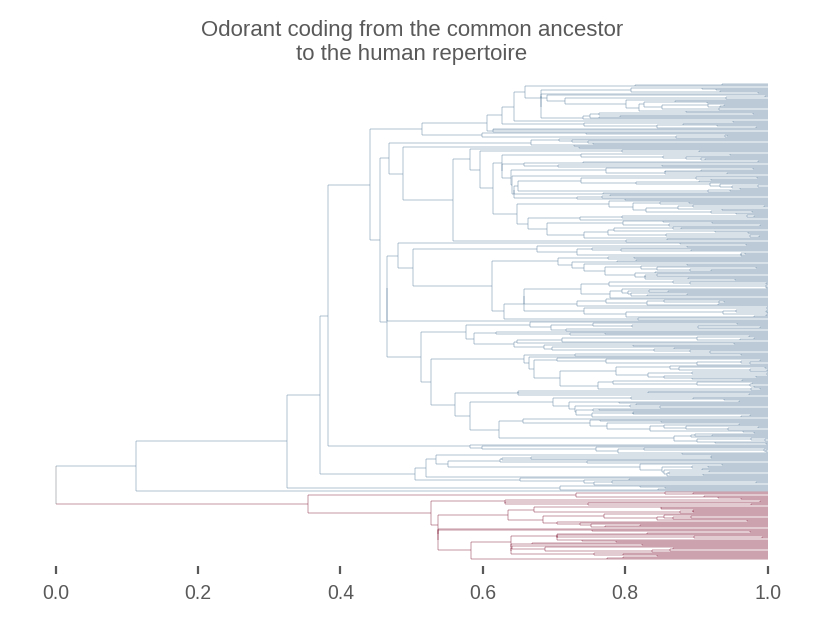

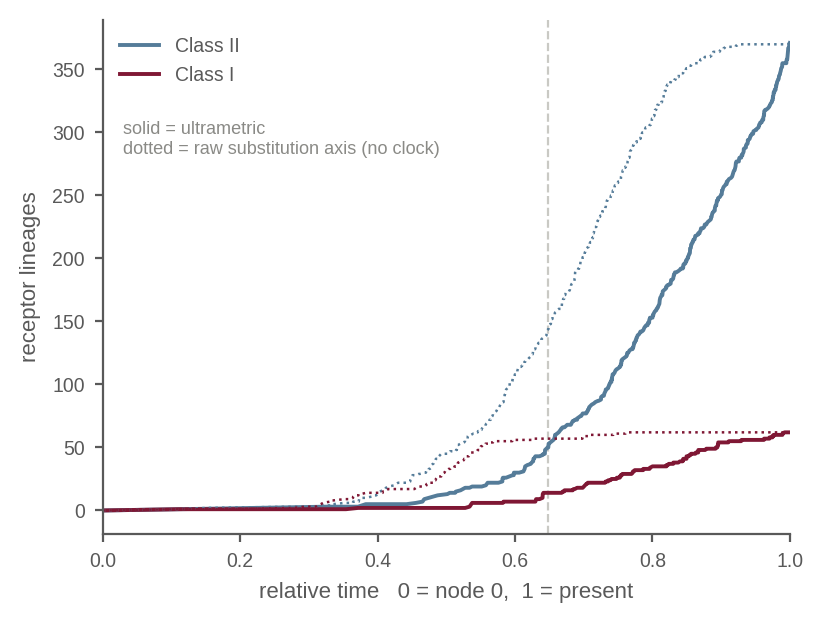

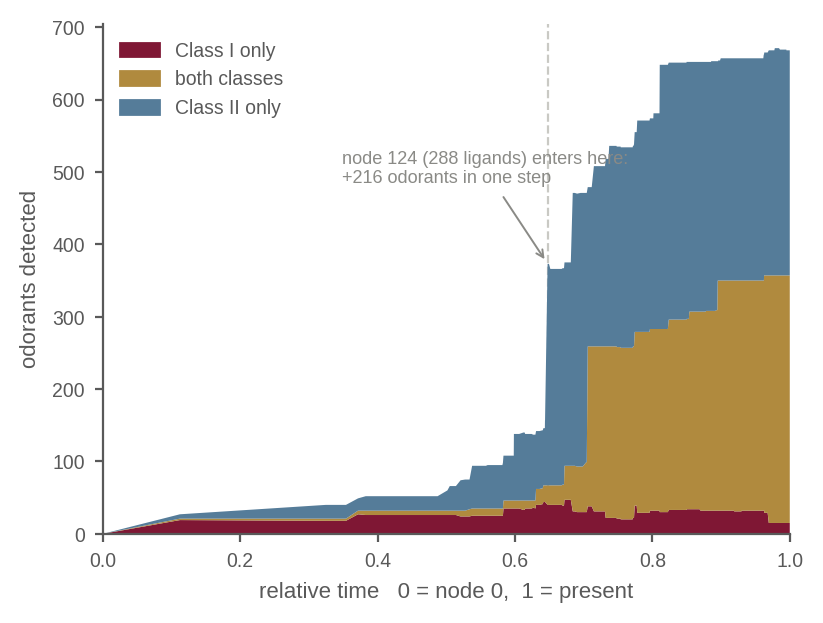

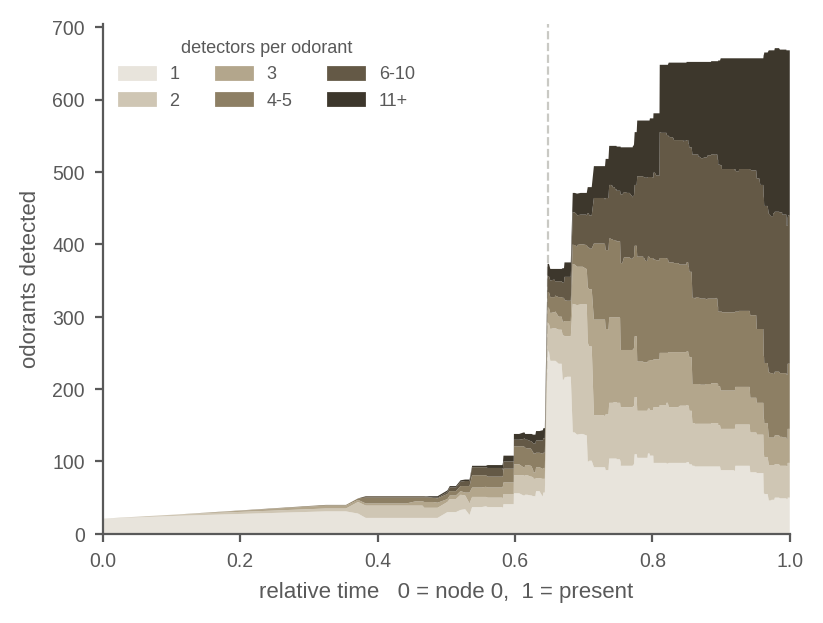

In [6]:
# the largest single step in the standing count, and the lineage that causes it
breadth = binary.sum(axis=1)
step_i = int(traj.n_detected.diff().abs().idxmax())
step_t = float(traj.t.iloc[step_i])
before = set(lineage_slice(mpl, float(traj.t.iloc[step_i - 1])))
after = set(lineage_slice(mpl, step_t))
entering = sorted(after - before, key=lambda n: (-int(breadth.get(n, 0)), n))[0]
jump = int(traj.n_detected.iloc[step_i] - traj.n_detected.iloc[step_i - 1])
entering_label = f"node {figure_node(entering)}" if entering.startswith("node_") else entering
print(f"largest step at t = {step_t:.4f}: {int(traj.n_detected.iloc[step_i - 1])} -> "
      f"{int(traj.n_detected.iloc[step_i])} odorants; broadest entering lineage "
      f"{entering} ({int(breadth[entering])} ligands)")

figures, axes = zip(*[plt.subplots(figsize=FIGSIZE, layout="constrained") for _ in range(4)])
draw_tree(axes[0], mpl, lw=0.16)
axes[0].set_title("Odorant coding from the common ancestor\nto the human repertoire")
axes[0].spines["bottom"].set_visible(False)

ax = axes[1]
ax.plot(traj.t, traj.n_class_II, color=CLASS2_COL, lw=1.4, label="Class II")
ax.plot(traj.t, traj.n_class_I, color=CLASS1_COL, lw=1.4, label="Class I")
ax.plot(traj_raw.t, traj_raw.n_class_II, color=CLASS2_COL, lw=0.9, ls=":")
ax.plot(traj_raw.t, traj_raw.n_class_I, color=CLASS1_COL, lw=0.9, ls=":")
ax.set_ylabel("receptor lineages")
ax.legend(loc="upper left")
ax.annotate("solid = ultrametric\ndotted = raw substitution axis (no clock)",
            xy=(0.03, 0.74), xycoords="axes fraction", fontsize=6.5, color="#8a8a86", ha="left")

ax = axes[2]
ax.stackplot(traj.t, traj.only_I, traj.both, traj.only_II,
             colors=[CLASS1_COL, BOTH_COL, CLASS2_COL], lw=0)
ax.set_ylabel("odorants detected")
ax.legend(handles=[Patch(color=CLASS1_COL, label="Class I only"),
                   Patch(color=BOTH_COL, label="both classes"),
                   Patch(color=CLASS2_COL, label="Class II only")],
          frameon=False, fontsize=7, loc="upper left")
step_y = float(traj.n_detected.iloc[step_i])
ax.annotate(f"{entering_label} ({int(breadth[entering])} ligands) enters here:\n"
            f"{jump:+d} odorants in one step",
            xy=(step_t, step_y), xytext=(step_t - 0.30, step_y * 1.3), fontsize=6.5,
            color="#8a8a86", arrowprops=dict(arrowstyle="->", color="#8a8a86", lw=0.7))

ax = axes[3]
cols = ["det_1", "det_2", "det_3", "det_4_5", "det_6_10", "det_11plus"]
labels = ["1", "2", "3", "4-5", "6-10", "11+"]
shades = ["#e8e4dc", "#cfc6b4", "#b3a68c", "#8d7f64", "#645946", "#3d372c"]
ax.stackplot(traj.t, *[traj[c] for c in cols], colors=shades, lw=0)
ax.set_ylabel("odorants detected")
ax.legend(handles=[Patch(color=s, label=l) for s, l in zip(shades, labels)],
          frameon=False, fontsize=6.5, loc="upper left", ncol=3, title="detectors per odorant",
          title_fontsize=6.5)
for a in axes[1:]:
    a.axvline(step_t, color=NULL_COL, ls="--", lw=0.8, zorder=0)
    a.set_xlim(0, 1)
    a.set_xlabel("relative time   0 = node 0,  1 = present")
for figure, part in zip(figures, ["tree", "receptors", "class_overlap", "detectors"]):
    save_fig(figure, f"trajectory_{part}")
plt.show()

8 of 412 steps decrease the standing odorant count; largest single drop -7 odorants
standing at t=1: 668   cumulative union over the whole sweep: 671


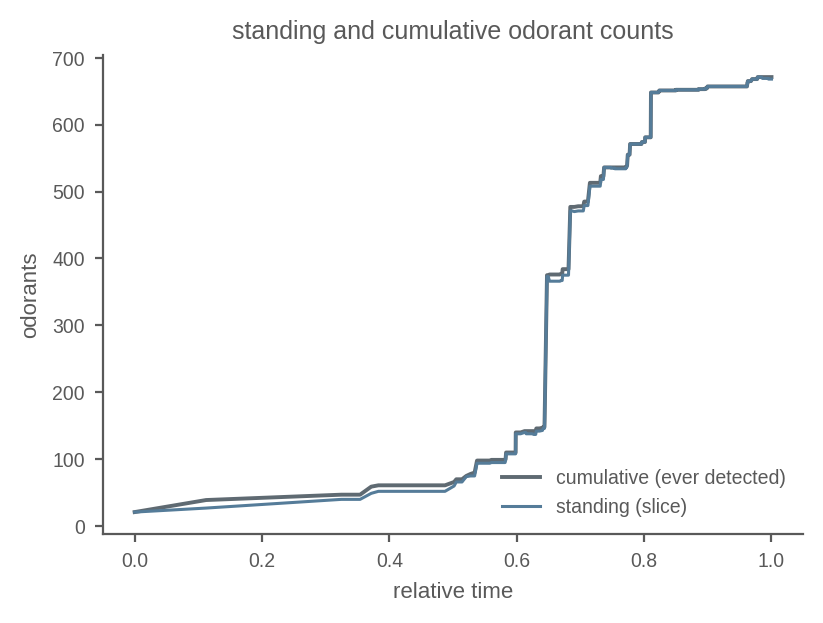

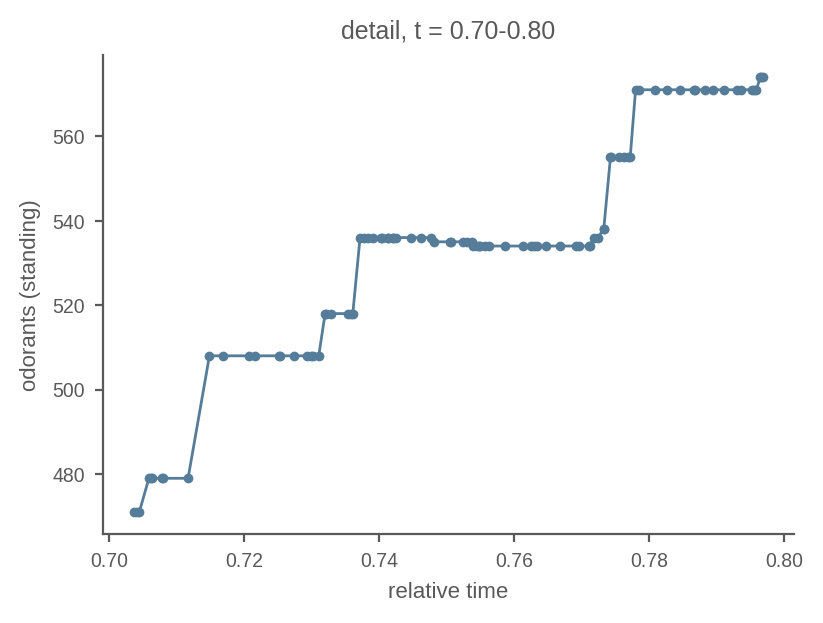

In [7]:
d = np.diff(traj.n_detected.values)
print(f"{int((d < 0).sum())} of {len(d)} steps decrease the standing odorant count; "
      f"largest single drop {int(d.min())} odorants")
print(f"standing at t=1: {int(traj.n_detected.iloc[-1])}   "
      f"cumulative union over the whole sweep: {int(traj.cum_detected.iloc[-1])}")

figures, axes = zip(*[plt.subplots(figsize=FIGSIZE, layout="constrained") for _ in range(2)])
ax = axes[0]
ax.plot(traj.t, traj.cum_detected, color=COMMON_COL, lw=1.4, label="cumulative (ever detected)")
ax.plot(traj.t, traj.n_detected, color=CLASS2_COL, lw=1.1, label="standing (slice)")
ax.set_xlabel("relative time"); ax.set_ylabel("odorants")
ax.legend(frameon=False, fontsize=7, loc="lower right")
ax.set_title("standing and cumulative odorant counts", fontsize=9)
ax = axes[1]
window = (traj.t > 0.70) & (traj.t < 0.80)
ax.plot(traj.t[window], traj.n_detected[window], color=CLASS2_COL, lw=1.0, marker="o", ms=2.5)
ax.set_xlabel("relative time"); ax.set_ylabel("odorants (standing)")
ax.set_title("detail, t = 0.70-0.80", fontsize=9)
save_fig(figures[0], "standing_vs_cumulative"); save_fig(figures[1], "standing_vs_cumulative_detail"); plt.show()

## The common ancestor's ligands

How many receptors detect each of node 0's ligands at every time, against all other ligands,
on 121 evenly spaced times. Writes `results/founder_ligands.csv`. Node 0's repertoire is
the top of its own predicted score row, so if the model scores some odorants highly for every
sequence, those would be node 0's ligands whatever the tree did.

node 0 (node_1) binds 21 odorants


median detectors at the present: node 0's ligands 95, others 6
node 0's ligands still detected at the present: 21 of 21


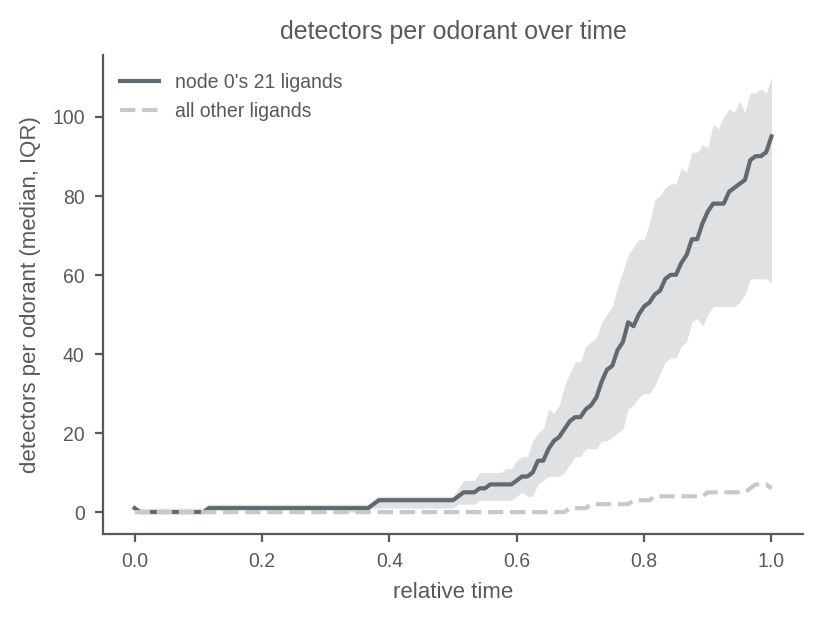

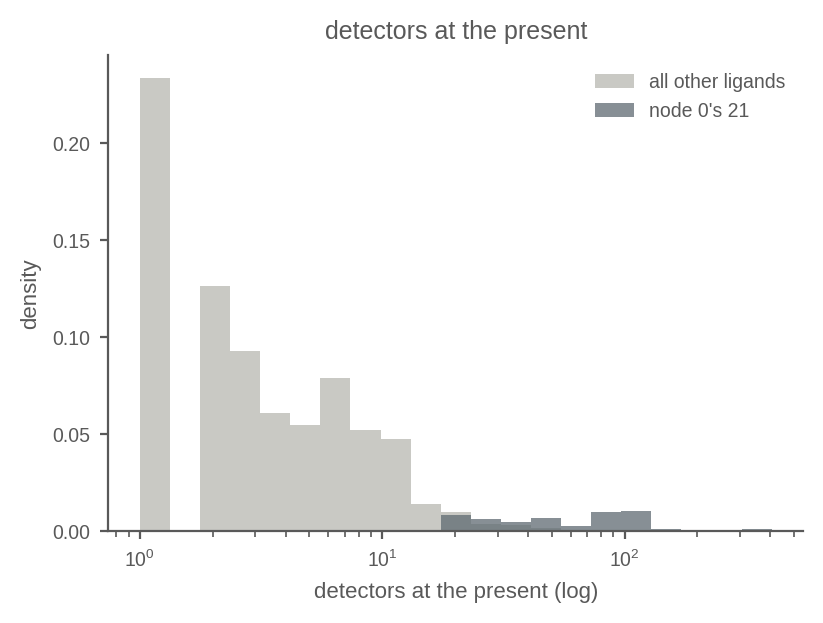

In [8]:
founders = list(binary.columns[binary.loc["node_1"].values])
others = [c for c in binary.columns if c not in founders]
print(f"node 0 (node_1) binds {len(founders)} odorants")

rows = []
for when in np.linspace(0, 1, 121):
    members = [m for m in lineage_slice(mpl, float(when)) if m in binary.index]
    block = binary.loc[members]
    det_f = block[founders].values.sum(0)
    det_o = block[others].values.sum(0)
    rows.append({"t": when, "n_lineages": len(members),
                 "founder_median": float(np.median(det_f)),
                 "founder_lo": float(np.percentile(det_f, 25)),
                 "founder_hi": float(np.percentile(det_f, 75)),
                 "other_median": float(np.median(det_o)),
                 "founder_still_detected": int((det_f > 0).sum())})
founder_traj = pd.DataFrame(rows)
save_table(founder_traj, "founder_ligands")

det_f = binary.loc[extant_I + extant_II, founders].values.sum(0)
det_o = binary.loc[extant_I + extant_II, others].values.sum(0)
print(f"median detectors at the present: node 0's ligands {int(np.median(det_f))}, "
      f"others {int(np.median(det_o))}")
print(f"node 0's ligands still detected at the present: "
      f"{int(founder_traj.founder_still_detected.iloc[-1])} of {len(founders)}")

figures, axes = zip(*[plt.subplots(figsize=FIGSIZE, layout="constrained") for _ in range(2)])
ax = axes[0]
ax.fill_between(founder_traj.t, founder_traj.founder_lo, founder_traj.founder_hi,
                color=COMMON_COL, alpha=0.20, lw=0)
ax.plot(founder_traj.t, founder_traj.founder_median, color=COMMON_COL, lw=1.5,
        label=f"node 0's {len(founders)} ligands")
ax.plot(founder_traj.t, founder_traj.other_median, color=NULL_COL, lw=1.5, ls="--",
        label="all other ligands")
ax.set_xlabel("relative time"); ax.set_ylabel("detectors per odorant (median, IQR)")
ax.legend(frameon=False, fontsize=7, loc="upper left")
ax.set_title("detectors per odorant over time", fontsize=9)
ax = axes[1]
bins = np.logspace(0, np.log10(max(det_f.max(), det_o.max()) + 1), 22)
ax.hist(det_o, bins=bins, color=NULL_COL, label="all other ligands", density=True)
ax.hist(det_f, bins=bins, color=COMMON_COL, alpha=0.75, label=f"node 0's {len(founders)}",
        density=True)
ax.set_xscale("log"); ax.set_xlabel("detectors at the present (log)")
ax.set_ylabel("density"); ax.legend(frameon=False, fontsize=7)
ax.set_title("detectors at the present", fontsize=9)
save_fig(figures[0], "founder_ligands_over_time"); save_fig(figures[1], "founder_ligands_at_present"); plt.show()

## Controls

**Composition.** At 40 times, draw extant receptors at random (200 draws) in the class ratio
the slice has at that time, with no tree, and compare the class-overlap counts with the
observed ones. Writes `results/composition_null.csv`.

**Ordering.** Resolve the same topology in 200 random orders of splits and read "class I
only" at 20 lineages: how much the count would depend on the order if repertoire size, not
time, were the axis.

**Independence.** With receptors independent at their observed breadths, the share of
detected odorants that would have two or more detectors anyway. Writes
`results/independence_null.csv`.

only_I    observed inside the null's 95% band at 100% of time points
both      observed inside the null's 95% band at 89% of time points
only_II   observed inside the null's 95% band at 100% of time points


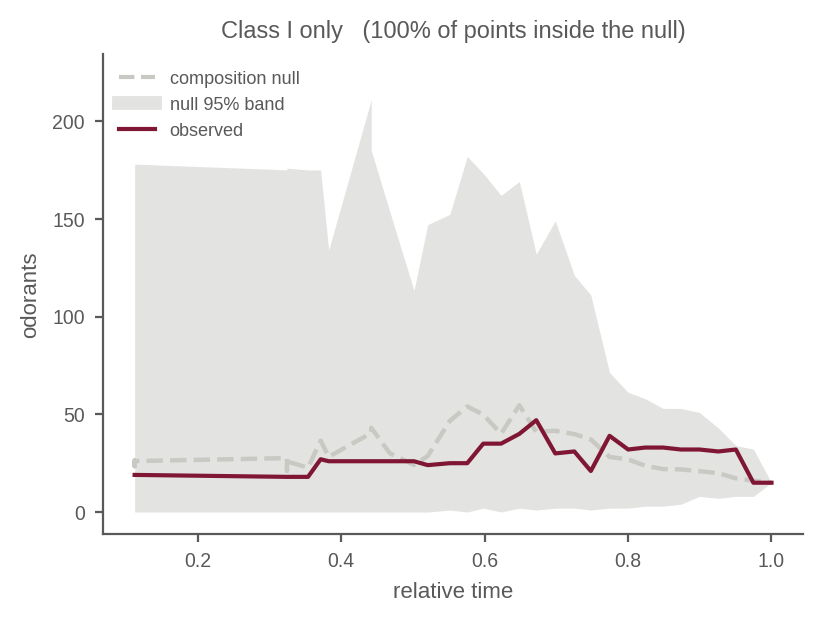

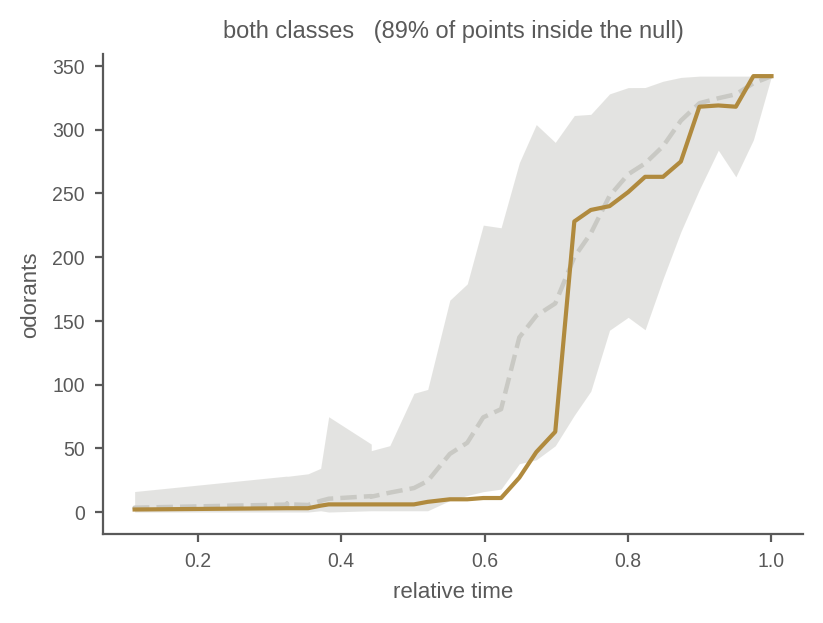

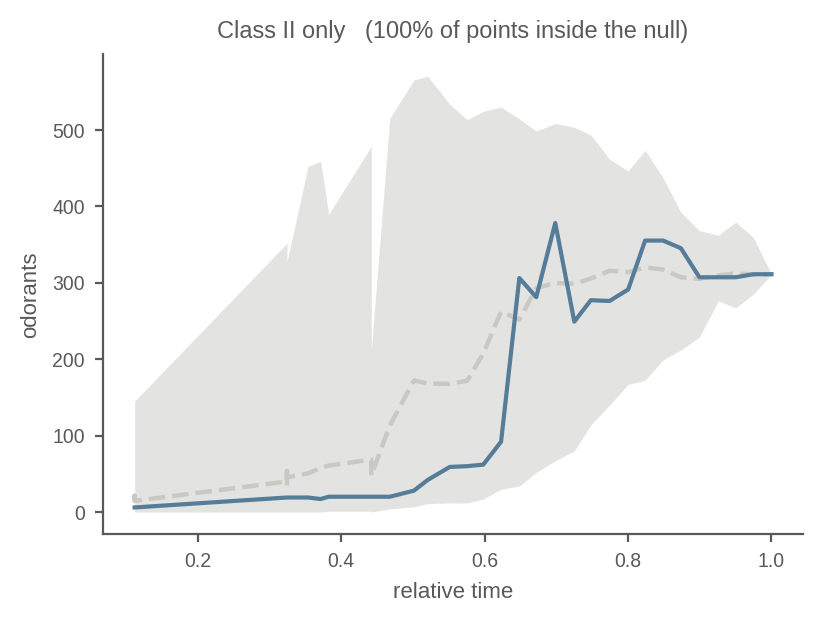

In [9]:
MI_all, MII_all = binary.loc[extant_I].values, binary.loc[extant_II].values
coarse = np.linspace(0.02, 1.0, 40)
N_DRAW = 200

comp = []
for when in coarse:
    row = traj.iloc[(traj.t - when).abs().argmin()]
    kI, kII = int(row.n_class_I), int(row.n_class_II)
    if kI == 0 and kII == 0:
        continue
    oi, bo, oii = [], [], []
    for _ in range(N_DRAW):
        if kI:
            a = MI_all[RNG.choice(len(MI_all), min(kI, len(MI_all)), replace=False)].sum(0) > 0
        else:
            a = np.zeros(MI_all.shape[1], bool)
        if kII:
            b = MII_all[RNG.choice(len(MII_all), min(kII, len(MII_all)), replace=False)].sum(0) > 0
        else:
            b = np.zeros(MII_all.shape[1], bool)
        oi.append((a & ~b).sum()); bo.append((a & b).sum()); oii.append((~a & b).sum())
    entry = {"t": float(row.t), "n_I": kI, "n_II": kII,
             "only_I_obs": float(row.only_I), "both_obs": float(row.both),
             "only_II_obs": float(row.only_II)}
    for key, draws in [("only_I", oi), ("both", bo), ("only_II", oii)]:
        lo, hi = np.percentile(draws, 2.5), np.percentile(draws, 97.5)
        entry[f"{key}_null"] = np.mean(draws)
        entry[f"{key}_lo"] = lo
        entry[f"{key}_hi"] = hi
        entry[f"{key}_inside"] = bool(lo <= entry[f"{key}_obs"] <= hi)
    comp.append(entry)
comp = pd.DataFrame(comp)
save_table(comp, "composition_null")
for key in ["only_I", "both", "only_II"]:
    print(f"{key:9s} observed inside the null's 95% band at "
          f"{comp[f'{key}_inside'].mean():.0%} of time points")

figures, axes = zip(*[plt.subplots(figsize=FIGSIZE, layout="constrained") for _ in range(3)])
for ax, key, col, name in [(axes[0], "only_I", CLASS1_COL, "Class I only"),
                           (axes[1], "both", BOTH_COL, "both classes"),
                           (axes[2], "only_II", CLASS2_COL, "Class II only")]:
    ax.fill_between(comp.t, comp[f"{key}_lo"], comp[f"{key}_hi"], color=NULL_COL, alpha=0.5, lw=0)
    ax.plot(comp.t, comp[f"{key}_null"], color=NULL_COL, lw=1.6, ls="--")
    ax.plot(comp.t, comp[f"{key}_obs"], color=col, lw=1.5)
    ax.set_xlabel("relative time")
    ax.set_title(f"{name}   ({comp[f'{key}_inside'].mean():.0%} of points inside the null)",
                 fontsize=8.5)
for ax in axes:
    ax.set_ylabel("odorants")
axes[0].legend(handles=[Line2D([], [], color=NULL_COL, ls="--", label="composition null"),
                        Line2D([], [], color=NULL_COL, lw=5, alpha=0.5, label="null 95% band"),
                        Line2D([], [], color=CLASS1_COL, label="observed")],
               frameon=False, fontsize=6.5, loc="upper left")
for figure, key in zip(figures, ["only_I", "both", "only_II"]): save_fig(figure, f"composition_null_{key}")
plt.show()

'Class I only' at 20 lineages over 200 random resolution orders: [13, 267], median 59
the tree's own slice nearest 20 lineages (t=0.527): only_I = 24, class I share of receptors 0.10
same on the raw axis (t=0.373): class I share 0.65
at  94 lineages: forced 78.4%, observed 70.7%
at 433 lineages: forced 100.0%, observed 92.5%


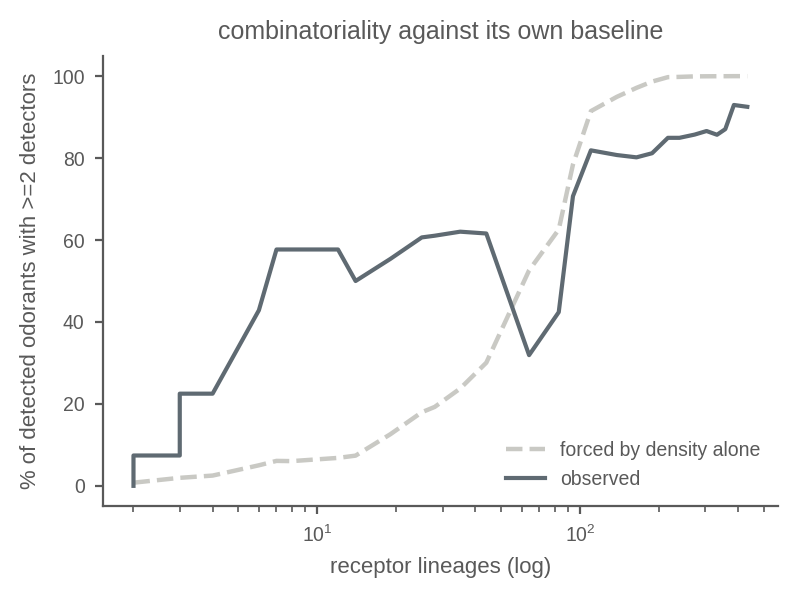

In [10]:
K = 20
spans = []
for _ in range(200):
    live = ["node_1"]
    while len(live) < K:
        internal = [i for i, m in enumerate(live) if not index[m].is_leaf]
        if not internal:
            break
        pick = live.pop(int(RNG.choice(internal)))
        live.extend(c.name for c in index[pick].children)
    members = [m for m in live if m in binary.index]
    in_i = [m for m in members if m in clades["Class_I"]]
    in_ii = [m for m in members if m in clades["Class_II"]]
    av = binary.loc[in_i].values.sum(0) > 0 if in_i else np.zeros(binary.shape[1], bool)
    bv = binary.loc[in_ii].values.sum(0) > 0 if in_ii else np.zeros(binary.shape[1], bool)
    spans.append(int((av & ~bv).sum()))
print(f"'Class I only' at {K} lineages over 200 random resolution orders: "
      f"[{min(spans)}, {max(spans)}], median {int(np.median(spans))}")
row20 = traj.iloc[(traj.n_lineages - K).abs().argmin()]
raw20 = traj_raw.iloc[(traj_raw.n_lineages - K).abs().argmin()]
print(f"the tree's own slice nearest {K} lineages (t={row20.t:.3f}): only_I = {int(row20.only_I)}, "
      f"class I share of receptors {row20.n_class_I / max(row20.n_lineages, 1):.2f}")
print(f"same on the raw axis (t={raw20.t:.3f}): class I share "
      f"{raw20.n_class_I / max(raw20.n_lineages, 1):.2f}")


def forced_combinatorial(rows):
    p = binary.loc[rows].values.mean(axis=1)          # each receptor's breadth as a rate
    none = np.prod(1 - p)
    exactly_one = sum(pi / (1 - pi) for pi in p if pi < 1) * none
    detected = 1 - none
    return (detected - exactly_one) / detected if detected > 0 else np.nan


ind = []
for when in coarse:
    members = [m for m in lineage_slice(mpl, float(when)) if m in binary.index]
    row = traj.iloc[(traj.t - when).abs().argmin()]
    obs = row.n_combinatorial / row.n_detected if row.n_detected else np.nan
    ind.append({"t": float(row.t), "n": len(members),
                "observed": obs, "forced": forced_combinatorial(members)})
ind = pd.DataFrame(ind)
save_table(ind, "independence_null")
for target in [100, 433]:
    r = ind.iloc[(ind.n - target).abs().argmin()]
    print(f"at {int(r.n):>3} lineages: forced {r.forced:.1%}, observed {r.observed:.1%}")

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(ind.n, ind.forced * 100, color=NULL_COL, lw=1.6, ls="--", label="forced by density alone")
ax.plot(ind.n, ind.observed * 100, color=COMMON_COL, lw=1.5, label="observed")
ax.set_xscale("log"); ax.set_xlabel("receptor lineages (log)")
ax.set_ylabel("% of detected odorants with >=2 detectors")
ax.legend(frameon=False, fontsize=7, loc="lower right")
ax.set_title("combinatoriality against its own baseline", fontsize=9)
plt.tight_layout(); save_fig(fig, "independence_null"); plt.show()

## Sensitivity

**Very broad rows.** The trajectory is repeated with every row calling more than 100 ligands
left out (`results/trajectory_blanked.csv`).

**Experimental overlay.** The extant endpoint with and without the measured M2OR values
written over the extant rows (`results/endpoint_overlay.csv`). Ancestral rows are the same
either way.

breadth, all 865 rows: median 6, max 572, 29 above 100
breadth, extant only: median 4, max 572
9606.Q9Y3N9    572
9606.O76001    543
9606.P34982    458
9606.P47890    402
node_314       390


all rows       largest single step  216 odorants (t=0.647), endpoint 668
blanked >100   largest single step   56 odorants (t=0.802), endpoint 371


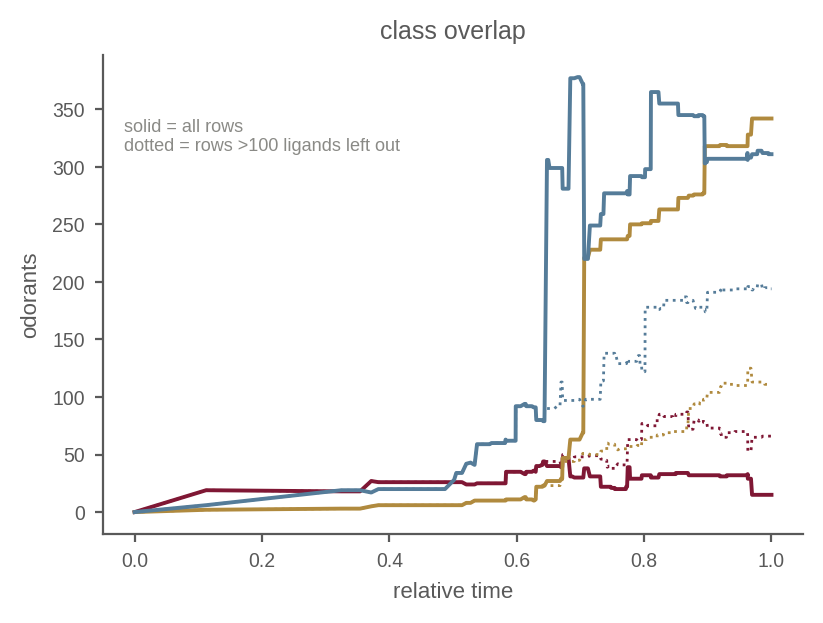

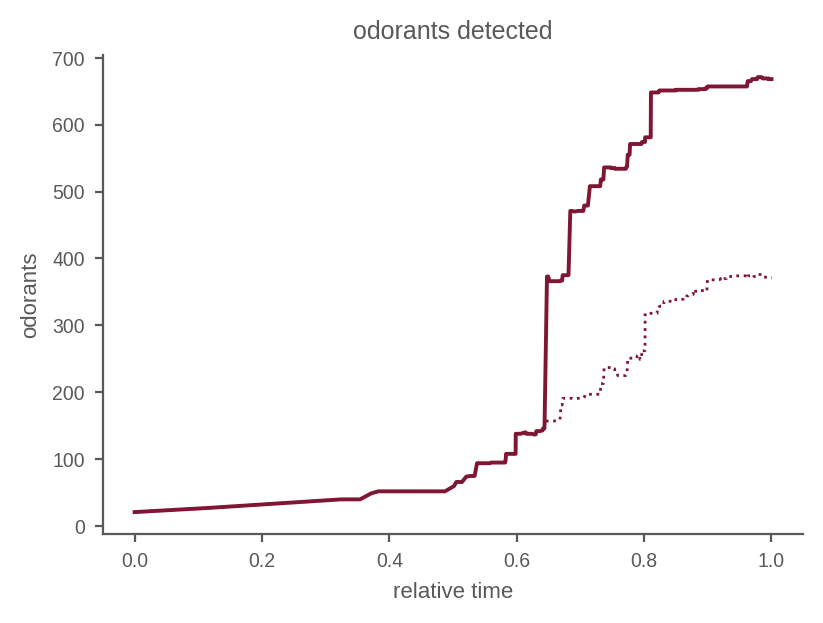

In [11]:
extant_breadth = breadth.loc[extant_I + extant_II]
print(f"breadth, all {len(breadth)} rows: median {int(breadth.median())}, "
      f"max {int(breadth.max())}, {int((breadth > 100).sum())} above 100")
print(f"breadth, extant only: median {int(extant_breadth.median())}, max {int(extant_breadth.max())}")
top5 = breadth.sort_values(ascending=False, kind="stable").head(5)
print(top5.to_string())

traj_blank = trajectory(mpl, blank_above=100)
save_table(traj_blank, "trajectory_blanked")
for name, frame in [("all rows", traj), ("blanked >100", traj_blank)]:
    step = frame.n_detected.diff().abs()
    print(f"{name:14s} largest single step {int(step.max()):>4} odorants "
          f"(t={frame.t[step.idxmax()]:.3f}), endpoint {int(frame.n_detected.iloc[-1])}")

figures, axes = zip(*[plt.subplots(figsize=FIGSIZE, layout="constrained") for _ in range(2)])
for ax, cols, title in [(axes[0], ["only_I", "both", "only_II"], "class overlap"),
                        (axes[1], ["n_detected"], "odorants detected")]:
    for c, col in zip(cols, [CLASS1_COL, BOTH_COL, CLASS2_COL]):
        ax.plot(traj.t, traj[c], color=col, lw=1.4)
        ax.plot(traj_blank.t, traj_blank[c], color=col, lw=1.0, ls=":")
    ax.set_xlabel("relative time"); ax.set_title(title, fontsize=9)
for ax in axes:
    ax.set_ylabel("odorants")
axes[0].annotate("solid = all rows\ndotted = rows >100 ligands left out",
                 xy=(0.03, 0.80), xycoords="axes fraction", fontsize=6.5, color="#8a8a86")
save_fig(figures[0], "sensitivity_broad_class_overlap"); save_fig(figures[1], "sensitivity_broad_detected"); plt.show()

In [12]:
overlaid, overlay_fill, measured = overlay_grid()
print(f"{len(measured)} measured cells, {int(measured.sum())} positive")

summary = []
for label, grid, fill in [("no overlay", binary, fills["extant"]),
                          ("with overlay", overlaid, overlay_fill)]:
    a = grid.loc[extant_I].values.sum(0) > 0
    b = grid.loc[extant_II].values.sum(0) > 0
    det = grid.loc[extant_I + extant_II].values.sum(0)
    summary.append({"fill": label, "cut": round(fill.cut, 4), "density": f"{fill.density:.4%}",
                    "only_I": int((a & ~b).sum()), "both": int((a & b).sum()),
                    "only_II": int((~a & b).sum()), "detected": int((det > 0).sum()),
                    "single": int((det == 1).sum()), "combinatorial": int((det >= 2).sum())})
summary = pd.DataFrame(summary)
save_table(summary, "endpoint_overlay")
print(summary.to_string(index=False))

23782 measured cells, 1128 positive
        fill    cut density  only_I  both  only_II  detected  single  combinatorial
  no overlay 0.8947 2.7453%      15   342      311       668      50            618
with overlay 0.8917 2.7453%      17   370      300       687      61            626
